# 03shortcut: travel times between the 32 cities in every era (1985 to 2026)

**What it does:** turns the "key links" of each era into a 32 x 32 table of travel times, using one method for every era so the eras can be compared:

1. **Key links.** About 70 links per era: Madrid to each city plus the main cross-country links. Each link has the time of the fastest direct train on it, in either direction.
   - 1985, 1993, 2001: read from the FFE timetable guides (`segments_<era>.csv`).
   - 2010, 2018: backcast from 2025, replacing only the links whose infrastructure changed (`segments_<era>.csv`).
   - 2025, 2026: fastest direct train found in the Renfe GTFS timetable, plus the two narrow-gauge links that are not in it (`segments_extra_2025_2026.csv`).
2. **Shortest paths.** The time between two cities is the quickest chain of key links, counting a **60 min penalty for each change of train**. The penalty stands for waiting for a connection; it was calibrated on 2025 (section 4).
3. **Checks.** Links that got slower from one era to the next, links slower than a detour, and how much the estimated links matter.

**Input:** `data/clean/cities.csv` (01cities), `data/raw/renfe/<version>/` (00renfegtfs), `data/clean/times_2025.csv` (02times, for the calibration), `data/raw/manual/segments_*.csv`.

**Output:** `data/clean/links_<era>.csv` (key links used, one row per link) and `data/clean/shortcut_<era>.csv` (32 x 32 table in minutes, symmetric) for each era; `figures/03madrid.png`.

## 0. Settings

In [1]:
from pathlib import Path
import datetime
import itertools
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

RAW_DIR = Path("data") / "raw" / "renfe"  # <- folder of the Renfe versions
MANUAL_DIR = Path("data") / "raw" / "manual"  # <- segment tables
CITIES_CSV = Path("data") / "clean" / "cities.csv"
FULL_2025_CSV = Path("data") / "clean" / "times_2025.csv"  # <- full timetable answer, for the calibration
OUT_DIR = Path("data") / "clean"
FIG_DIR = Path("figures")
MANUAL_ERAS = ["1985", "1993", "2001", "2010", "2018"]  # <- eras compiled by hand
GTFS_ERAS = {}
GTFS_ERAS["2025"] = ("2025-12-18", datetime.date(2026, 1, 14))  # <- (timetable version, day), as in 02times
GTFS_ERAS["2026"] = ("2026-11-16", datetime.date(2026, 11, 25))
ERAS = MANUAL_ERAS + list(GTFS_ERAS)
CHANGE_PENALTY = 60  # <- minutes added for each change of train
SHIFT = 20  # <- minutes added to and taken from each estimated link in the sensitivity check
GTFS_NOTES = {}
GTFS_NOTES[("2026", "Córdoba", "Jaén")] = "Renfe replacement bus coded as a train in the GTFS (no intermediate stops; line closed for works, buses until autumn 2027)"  # <- extra note on a GTFS link

## 1. Read the hand-compiled eras

In [2]:
cities = pd.read_csv(CITIES_CSV, dtype={"main_stop_id": str, "stop_ids": str})
names = list(cities["city"])

def read_segments(path):
    table = pd.read_csv(path, dtype=str, keep_default_na=False)
    table["minutes"] = table["minutes"].astype(float)
    unknown = set(table["city_a"]).union(table["city_b"]) - set(names)
    if unknown:
        raise ValueError(f"{path.name}: unknown city names {unknown}")
    return table

links = {}
for era in MANUAL_ERAS:
    links[era] = read_segments(MANUAL_DIR / f"segments_{era}.csv")
    print(f"{era}: {len(links[era])} links")

# every pair that is a key link in at least one hand-compiled era: the same list is used for 2025 and 2026
LINK_PAIRS = sorted({tuple(sorted(p)) for era in MANUAL_ERAS for p in zip(links[era]["city_a"], links[era]["city_b"])})
print(len(LINK_PAIRS), "different links over the hand-compiled eras")

1985: 69 links
1993: 72 links
2001: 72 links
2010: 72 links
2018: 70 links
73 different links over the hand-compiled eras


## 2. Key links for 2025 and 2026 from the Renfe timetable

In [3]:
def read_gtfs(folder, name):
    table = pd.read_csv(folder / name, dtype=str, keep_default_na=False, encoding="utf-8-sig", skipinitialspace=True)
    table.columns = [c.strip() for c in table.columns]
    for column in table.columns:
        table[column] = table[column].str.strip()
    return table

def to_minutes(text):
    h, m, s = text.split(":")
    return int(h) * 60 + int(m) + int(s) / 60

def clock(minutes):
    m = int(round(minutes))
    return f"{m // 60:02d}:{m % 60:02d}"

def fastest_direct(version, service_date):
    """Fastest direct train between every pair of cities on one day (either direction)."""
    folder = RAW_DIR / version
    calendar = read_gtfs(folder, "calendar.txt")
    calendar_dates = read_gtfs(folder, "calendar_dates.txt")
    trips = read_gtfs(folder, "trips.txt")
    routes = read_gtfs(folder, "routes.txt")
    stop_times = read_gtfs(folder, "stop_times.txt")
    day = service_date.strftime("%Y%m%d")
    weekday = service_date.strftime("%A").lower()
    running = calendar[(calendar[weekday] == "1") & (calendar["start_date"] <= day) & (calendar["end_date"] >= day)]
    services = set(running["service_id"])
    services -= set(calendar_dates.loc[(calendar_dates["date"] == day) & (calendar_dates["exception_type"] == "2"), "service_id"])
    services |= set(calendar_dates.loc[(calendar_dates["date"] == day) & (calendar_dates["exception_type"] == "1"), "service_id"])
    day_trips = trips[trips["service_id"].isin(services)].merge(routes[["route_id", "route_short_name"]], on="route_id", how="left")
    label = dict(zip(day_trips["trip_id"], day_trips["route_short_name"] + " " + day_trips["trip_short_name"]))
    stop_city = {}
    for name, ids in zip(cities["city"], cities["stop_ids"]):
        for s in ids.split(";"):
            stop_city[s] = name
    st = stop_times[stop_times["trip_id"].isin(set(day_trips["trip_id"])) & stop_times["stop_id"].isin(set(stop_city))].copy()
    st["seq"] = st["stop_sequence"].astype(int)
    st = st.sort_values(["trip_id", "seq"])
    best = {}
    for trip_id, group in st.groupby("trip_id", sort=False):
        calls = list(zip(group["stop_id"].map(stop_city), group["arrival_time"].map(to_minutes), group["departure_time"].map(to_minutes)))
        for (c1, _, dep), (c2, arr, _) in itertools.combinations(calls, 2):
            if c1 == c2:
                continue
            key = tuple(sorted((c1, c2)))
            if key not in best or arr - dep < best[key][0]:
                best[key] = (arr - dep, label[trip_id], clock(dep), clock(arr), c1)
    print(f"{version} {service_date}: {len(day_trips)} trips that day")
    return best

extra = read_segments(MANUAL_DIR / "segments_extra_2025_2026.csv")
for era, (version, service_date) in GTFS_ERAS.items():
    best = fastest_direct(version, service_date)
    rows = []
    for a, b in LINK_PAIRS:
        if (a, b) in best:
            minutes, train, depart, arrive, from_city = best[(a, b)]
            rows.append({"city_a": a, "city_b": b, "minutes": round(minutes), "train": train, "depart": depart, "arrive": arrive, "from_station": from_city, "note": f"Renfe GTFS {version}, {service_date}" + ("; " + GTFS_NOTES[(era, a, b)] if (era, a, b) in GTFS_NOTES else "")})
    table = pd.DataFrame(rows)
    in_table = {tuple(sorted(p)) for p in zip(table["city_a"], table["city_b"])}
    added = extra[[tuple(sorted(p)) not in in_table for p in zip(extra["city_a"], extra["city_b"])]]
    links[era] = pd.concat([table, added], ignore_index=True)
    no_train = [p for p in LINK_PAIRS if p not in best and p not in {tuple(sorted(q)) for q in zip(added["city_a"], added["city_b"])}]
    print(f"  {era}: {len(links[era])} links ({len(added)} narrow gauge added); no direct train on: {no_train}")

for era in ERAS:
    links[era].to_csv(OUT_DIR / f"links_{era}.csv", index=False, encoding="utf-8")

2025-12-18 2026-01-14: 1446 trips that day
  2025: 73 links (2 narrow gauge added); no direct train on: []
2026-11-16 2026-11-25: 1610 trips that day
  2026: 73 links (2 narrow gauge added); no direct train on: []


**Note:** a link with no direct train in a given era is simply left out; the shortest-path step then routes around it with a change.

## 3. Shortest paths with a change penalty

In [4]:
def shortcut_matrix(table, penalty=CHANGE_PENALTY):
    graph = nx.Graph()
    graph.add_nodes_from(names)
    for a, b, minutes in zip(table["city_a"], table["city_b"], table["minutes"]):
        weight = minutes + penalty
        if graph.has_edge(a, b):
            weight = min(weight, graph[a][b]["w"])
        graph.add_edge(a, b, w=weight)
    matrix = pd.DataFrame(np.nan, index=names, columns=names)
    for a in names:
        lengths = nx.single_source_dijkstra_path_length(graph, a, weight="w")
        for b, total in lengths.items():
            matrix.loc[a, b] = 0.0 if a == b else total - penalty  # one penalty too many: the first train is not a change
    return matrix

shortcut = {}
for era in ERAS:
    shortcut[era] = shortcut_matrix(links[era])
    shortcut[era].round(0).to_csv(OUT_DIR / f"shortcut_{era}.csv", encoding="utf-8")
    unreachable = int(shortcut[era].isna().sum().sum())
    print(f"{era}: saved shortcut_{era}.csv; pairs with no route: {unreachable}")

1985: saved shortcut_1985.csv; pairs with no route: 0
1993: saved shortcut_1993.csv; pairs with no route: 0
2001: saved shortcut_2001.csv; pairs with no route: 0
2010: saved shortcut_2010.csv; pairs with no route: 0
2018: saved shortcut_2018.csv; pairs with no route: 0
2025: saved shortcut_2025.csv; pairs with no route: 0
2026: saved shortcut_2026.csv; pairs with no route: 0


## 4. Calibration: shortcut against the full timetable answer, 2025

In [5]:
full = pd.read_csv(FULL_2025_CSV, index_col=0).reindex(index=names, columns=names)
full = (full + full.T) / 2  # the shortcut is symmetric, so compare with the mean of both directions
pairs = [(a, b) for a, b in itertools.combinations(names, 2)]

def compare(matrix):
    err = pd.Series([matrix.loc[a, b] - full.loc[a, b] for a, b in pairs])
    return err

for penalty in [30, 45, 60, 75, 90]:
    err = compare(shortcut_matrix(links["2025"], penalty))
    print(f"penalty {penalty:3d} min: median error {err.median():6.1f}, median absolute error {err.abs().median():5.1f}, within 30 min {(err.abs() <= 30).mean():.0%}")

err = compare(shortcut["2025"])
check = pd.DataFrame(pairs, columns=["a", "b"])
check["full"] = [full.loc[a, b] for a, b in pairs]
check["shortcut"] = [shortcut["2025"].loc[a, b] for a, b in pairs]
check["error"] = err
print()
print("Largest gaps with the chosen penalty:")
print(check.reindex(check["error"].abs().sort_values(ascending=False).index).head(8).round(0).to_string(index=False))

penalty  30 min: median error  -25.0, median absolute error  29.2, within 30 min 51%
penalty  45 min: median error   -9.0, median absolute error  20.2, within 30 min 61%
penalty  60 min: median error   -1.0, median absolute error  20.5, within 30 min 64%
penalty  75 min: median error   10.0, median absolute error  23.0, within 30 min 57%
penalty  90 min: median error   25.5, median absolute error  33.5, within 30 min 46%

Largest gaps with the chosen penalty:
        a             b  full  shortcut  error
Santander        Bilbao 508.0     190.0 -318.0
  Badajoz        Bilbao 875.0     606.0 -269.0
     Jaén        Bilbao 756.0     570.0 -186.0
     Vigo        Huelva 686.0     527.0 -160.0
  Sevilla       Badajoz 326.0     484.0  158.0
 Albacete          Jaén 229.0     385.0  156.0
  Almería     Santander 858.0     716.0 -142.0
Tarragona San Sebastián 344.0     484.0  140.0


**How to read it:** the error is shortcut minus full timetable answer. The full answer knows the real connection times of that day; the shortcut only assumes 60 min per change. The aim is not an exact match pair by pair but no bias overall (median error near 0), so the eras compare fairly.

## 5. Check: links that got slower from one era to the next

In [6]:
def as_dict(table):
    out = {}
    for a, b, minutes, note in zip(table["city_a"], table["city_b"], table["minutes"], table["note"]):
        key = tuple(sorted((a, b)))
        out[key] = min(minutes, out.get(key, (1e9, ""))[0]), note
    return out

slower = []
for before, after in zip(ERAS[:-1], ERAS[1:]):
    d1, d2 = as_dict(links[before]), as_dict(links[after])
    for key in sorted(set(d1) & set(d2)):
        change = d2[key][0] - d1[key][0]
        if change >= 10:
            slower.append({"eras": f"{before} to {after}", "link": f"{key[0]} - {key[1]}", "before": d1[key][0], "after": d2[key][0], "change": change, "note_after": d2[key][1][:70]})
slower = pd.DataFrame(slower)
print(f"{len(slower)} links at least 10 min slower than in the era before:")
print(slower.to_string(index=False))

27 links at least 10 min slower than in the era before:
        eras                       link  before  after  change                                                             note_after
1985 to 1993              Jaén - Madrid   239.0  266.0    27.0                                                                       
1985 to 1993          Teruel - Valencia   161.0  176.0    15.0                                                                       
1985 to 1993          Teruel - Zaragoza   158.0  170.0    12.0                                                                       
1993 to 2001          Bilbao - Zaragoza   270.0  280.0    10.0                                                                       
1993 to 2001              Madrid - Vigo   475.0  485.0    10.0                                    also Talgo 74 Vigo to Madrid at 485
2018 to 2025          Albacete - Murcia   101.0  113.0    12.0                                      Renfe GTFS 2025-12-18, 2026-01-14
2018 t

**Expected cases:** 2025 to 2026 (speed restrictions after the Adamuz accident); Granada around 2018 (station closed 2015 to 2019, AVE plus bus); a train type withdrawn from a link (the link then uses a slower service). Anything else is worth a look.

## 6. Check: direct links slower than a detour

In [7]:
detours = []
for era in ERAS:
    for a, b, minutes in zip(links[era]["city_a"], links[era]["city_b"], links[era]["minutes"]):
        others = links[era][~(((links[era]["city_a"] == a) & (links[era]["city_b"] == b)) | ((links[era]["city_a"] == b) & (links[era]["city_b"] == a)))]
        alt = shortcut_matrix(others, penalty=0).loc[a, b]  # detour with no change penalty at all
        if alt < minutes - 15:
            detours.append({"era": era, "link": f"{a} - {b}", "direct": minutes, "detour_no_penalty": round(alt), "gap": round(minutes - alt)})
detours = pd.DataFrame(detours)
print(f"{len(detours)} direct links more than 15 min slower than a detour even before counting any change:")
print(detours.to_string(index=False) if len(detours) else "none")

63 direct links more than 15 min slower than a detour even before counting any change:
 era                   link  direct  detour_no_penalty  gap
1985      Madrid - Pamplona   371.0                353   18
1985          Madrid - Vigo   494.0                472   22
1985        Madrid - Murcia   293.0                277   16
1985         Madrid - Cádiz   460.0                443   17
1985        Madrid - Huelva   453.0                436   17
1985     Barcelona - Bilbao   547.0                514   33
1993        Madrid - Girona   529.0                461   68
1993        Madrid - Murcia   255.0                234   21
1993         Madrid - Cádiz   300.0                236   64
1993          Madrid - Jaén   266.0                200   66
1993        Madrid - Huelva   275.0                211   64
1993        Madrid - Málaga   280.0                249   31
1993     Barcelona - Bilbao   530.0                475   55
2001      Madrid - A Coruña   500.0                483   17
2001         

**How to read it:** such a link never shapes the map (the detour is always faster), so it is harmless, but it can point to a typo or a slow train type picked by mistake.

## 7. Check: how much do the estimated links matter?

In [8]:
sens = []
for era in MANUAL_ERAS:
    table = links[era]
    base = shortcut[era]
    for i in table.index[table["note"].str.contains("estimate", case=False)]:
        worst = 0
        moved = 0
        for sign in (1, -1):
            changed = table.copy()
            changed.loc[i, "minutes"] = changed.loc[i, "minutes"] + sign * SHIFT
            diff = (shortcut_matrix(changed) - base).abs()
            worst = max(worst, diff.max().max())
            moved = max(moved, int((diff.values[np.triu_indices(len(names), 1)] >= 10).sum()))
        sens.append({"era": era, "link": f"{table.loc[i, 'city_a']} - {table.loc[i, 'city_b']}", "minutes": table.loc[i, "minutes"], "largest_change": worst, "pairs_moved_10min": moved})
sens = pd.DataFrame(sens)
print(f"Each estimated link moved by +/-{SHIFT} min; effect on the {len(names) * (len(names) - 1) // 2} city pairs:")
print(sens.to_string(index=False))

Each estimated link moved by +/-20 min; effect on the 496 city pairs:
 era                   link  minutes  largest_change  pairs_moved_10min
1985 Bilbao - San Sebastián    155.0            20.0                  4
1985         Córdoba - Jaén    102.0            20.0                  7
1985    Albacete - Alicante    125.0            20.0                  1
1993 Bilbao - San Sebastián    155.0            20.0                  4
1993         Córdoba - Jaén    102.0            20.0                 31
1993    Albacete - Alicante     99.0            20.0                  1
1993  Ciudad Real - Córdoba     49.0            20.0                 14
2001 Bilbao - San Sebastián    155.0            20.0                  4
2001         Córdoba - Jaén    102.0            20.0                 31
2001    Albacete - Alicante     88.0            20.0                  1
2001  Ciudad Real - Córdoba     51.0            20.0                 14
2010      Madrid - A Coruña    376.0            20.0              

**How to read it:** a link with few pairs moved only affects its own two cities; a link that moves many pairs carries traffic for a whole region, and its estimate deserves a second source.

## 8. Results: from Madrid, every era

In [9]:
madrid = pd.DataFrame({era: shortcut[era].loc["Madrid"] for era in ERAS}).drop(index="Madrid")
madrid = madrid.sort_values("2025")
print(madrid.round(0).astype("Int64").to_string())

               1985  1993  2001  2010  2018  2025  2026
Ciudad Real     117    49    50    50    50    54    53
Valladolid      170   146   143    56    54    54    54
Zaragoza        202   182   175    78    78    78    95
Albacete        158   126   119    90    90    90    90
Córdoba         280    98   101   101   101   104   104
Valencia        282   235   205    95   100   114   114
León            259   243   230   170   126   116   116
Lleida          325   275   280   122   122   122   143
Tarragona       421   376   355   124   124   124   147
Ourense         365   345   350   262   223   134   134
Alicante        283   225   207   190   140   143   143
Barcelona       441   395   395   158   150   157   182
Sevilla         356   145   135   135   135   158   156
Málaga          439   280   242   140   140   159   164
Murcia          293   255   226   215   215   165   165
Santiago        472   440   439   355   261   180   177
Pamplona        371   305   288   185   185   18

In [10]:
def median_ratio(era, base="1985"):
    ratios = [shortcut[era].loc[a, b] / shortcut[base].loc[a, b] for a, b in pairs]
    return np.nanmedian(ratios)

print("Median city pair, as a share of its 1985 time:")
for era in ERAS:
    print(f"  {era}: {median_ratio(era):.2f}")

Median city pair, as a share of its 1985 time:
  1985: 1.00
  1993: 0.90
  2001: 0.86
  2010: 0.67
  2018: 0.62
  2025: 0.57
  2026: 0.58


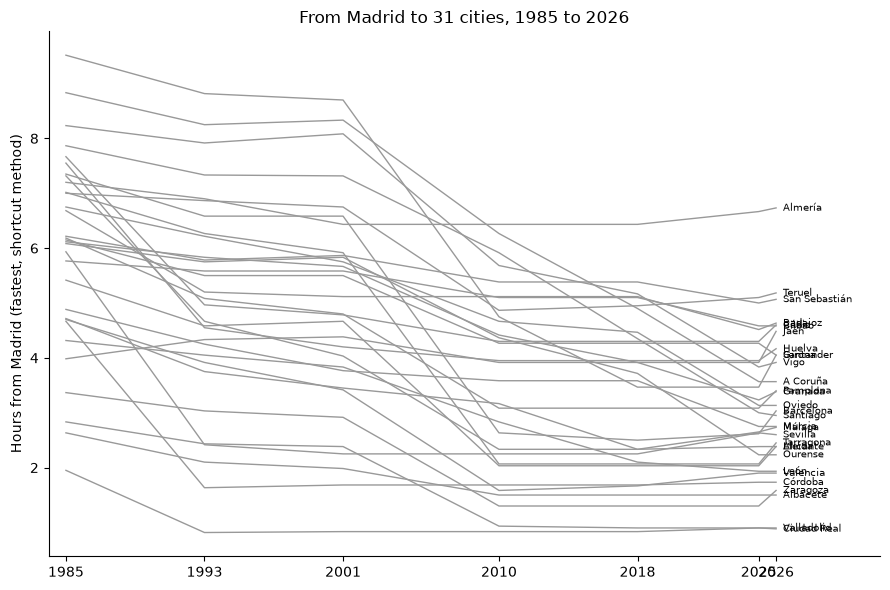

In [11]:
FIG_DIR.mkdir(exist_ok=True)
years = [int(e) for e in ERAS]
fig, ax = plt.subplots(figsize=(9, 6))
for city in madrid.index:
    ax.plot(years, madrid.loc[city] / 60, color="0.6", linewidth=1)
    ax.text(years[-1] + 0.4, madrid.loc[city, ERAS[-1]] / 60, city, fontsize=7, va="center")
ax.set_xticks(years)
ax.set_ylabel("Hours from Madrid (fastest, shortcut method)")
ax.set_xlim(years[0] - 1, years[-1] + 6)
ax.set_title("From Madrid to 31 cities, 1985 to 2026")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(FIG_DIR / "03madrid.png", dpi=150)
plt.show()

**Note:** this chart is a working check, not a figure for the piece: overlapping labels are expected.

___
**END**